# Итоговая работа: Анализ продаж интернет-магазина (E-Commerce Orders)

**Студент:** Минаев В.В.
**Программа:** «Аналитик данных»
**Датасет:** E-Commerce Orders (Kaggle)

## Импорт библиотек и настройка окружения

В данном блоке подключаются основные библиотеки для анализа данных, визуализации и машинного обучения:
- `pandas` и `numpy` — для обработки табличных данных и математических вычислений;
- `matplotlib` и `seaborn` — для построения графиков;
- `scikit-learn` и `xgboost` — для обучения моделей;
- `statsmodels` — для статистической интерпретации (p-value).

Также настраивается стиль графиков и отключаются технические предупреждения для чистоты вывода.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve
import statsmodels.api as sm

# Отключаем лишние предупреждения для чистоты вывода
warnings.filterwarnings('ignore')

# Настройка стиля графиков
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
print("✅ Библиотеки загружены.")

✅ Библиотеки загружены.


## Глава 1. Предварительная обработка данных (ETL) и разведочный анализ (EDA)

В данном блоке выполняется:
1. **Загрузка исходного датасета** из папки `input` и удаление дубликатов.
2. **Обработка пропусков** и приведение типов данных.
3. **Создание новых признаков** (итоговая сумма заказа, год, месяц, квартал).
4. **Расчет базовых метрик**: доля возвратов, выручка по категориям, корреляции.
5. **Построение трех графиков** для визуального анализа (выручка по категориям, динамика по месяцам, корреляционная матрица).

Результат: очищенный датасет `cleaned_ecommerce_data.csv` и графики `Figure_1` — `Figure_3` в папке `output`.


--- ГЛАВА 1: ЗАГРУЗКА, ОЧИСТКА (ETL) И EDA ---
Исходное количество строк: 10035
Удалено дубликатов: 9. Осталось строк: 10026
Очищенный файл сохранен как 'output/cleaned_ecommerce_data.csv'

--- 2. АНАЛИЗ ВОЗВРАТОВ ---
Доля возвратов: 17.34%

--- 3. ВЫРУЧКА ПО КАТЕГОРИЯМ (%) ---
product_category
Electronics       20.16
Clothing          15.38
Home & Kitchen    11.80
Books             10.13
Sports             7.84
Beauty             6.84
Toys               6.56
Food               4.26
Automotive         3.85
Garden             2.99
Other              2.91
Pet Supplies       2.27
Music              1.76
Office             1.72
Jewelry            1.53
Name: total_amount, dtype: float64

--- 4. ВОЗВРАТЫ ПО КАТЕГОРИЯМ (ТОП-5) ---
product_category
Clothing          25.65
Electronics       21.19
Automotive        20.24
Home & Kitchen    18.05
Beauty            17.01
Name: is_returned, dtype: float64

--- 5. КОРРЕЛЯЦИИ ---
Скидка и возврат: 0.1384
Стаж клиента и возврат: 0.0024
Предыдущие зака

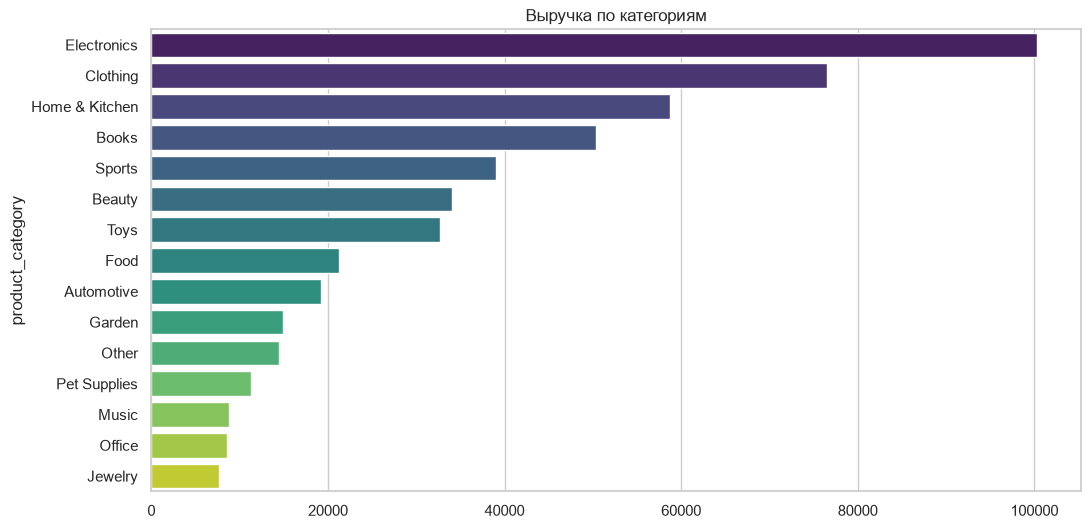

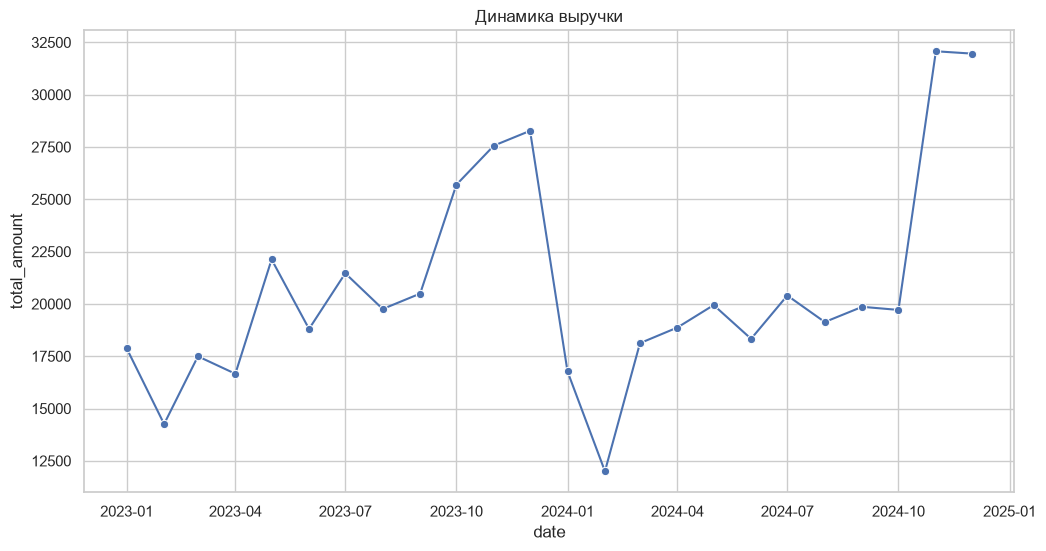

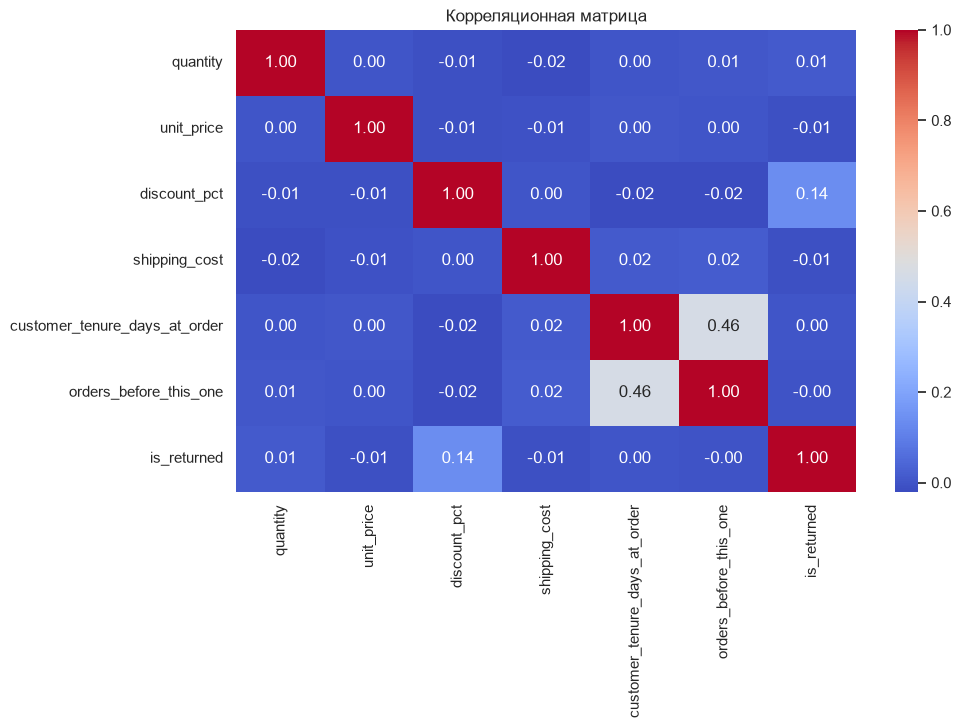


✅ Глава 1 успешно выполнена. Все данные и графики сохранены в папку 'output'.


In [2]:
print("\n--- ГЛАВА 1: ЗАГРУЗКА, ОЧИСТКА (ETL) И EDA ---")

# Создаем папку output, если ее нет
os.makedirs('output', exist_ok=True)

# Умный поиск исходного файла
raw_path = 'input/ecommerce_orders.csv'
if not os.path.exists(raw_path):
    raw_path = 'ecommerce_orders.csv' # Если файл лежит рядом с блокнотом

if not os.path.exists(raw_path):
    raise FileNotFoundError("❌ Файл 'ecommerce_orders.csv' не найден! Положи его в папку 'input'.")

df = pd.read_csv(raw_path)
print(f"Исходное количество строк: {len(df)}")

# Удаление дубликатов
dup = df.duplicated().sum()
df = df.drop_duplicates()
print(f"Удалено дубликатов: {dup}. Осталось строк: {len(df)}")

# Обработка пропусков
df['device_type'] = df['device_type'].fillna(df['device_type'].mode()[0])
df['country'] = df['country'].fillna('Unknown')

# Конвертация дат и создание новых признаков
df['order_date'] = pd.to_datetime(df['order_date'])
df['total_amount'] = df['quantity'] * df['unit_price'] * (1 - df['discount_pct'] / 100) + df['shipping_cost']
df['year'] = df['order_date'].dt.year
df['month'] = df['order_date'].dt.month
df['quarter'] = df['order_date'].dt.quarter

# Сохранение очищенного файла в папку output
df.to_csv('output/cleaned_ecommerce_data.csv', index=False)
print("Очищенный файл сохранен как 'output/cleaned_ecommerce_data.csv'")

print("\n--- 2. АНАЛИЗ ВОЗВРАТОВ ---")
return_pct = (df['is_returned'].value_counts(normalize=True) * 100).round(2)
print(f"Доля возвратов: {return_pct.get(1, 0)}%")

print("\n--- 3. ВЫРУЧКА ПО КАТЕГОРИЯМ (%) ---")
cat_rev = df.groupby('product_category')['total_amount'].sum().sort_values(ascending=False)
cat_rev_pct = (cat_rev / cat_rev.sum() * 100).round(2)
print(cat_rev_pct)

print("\n--- 4. ВОЗВРАТЫ ПО КАТЕГОРИЯМ (ТОП-5) ---")
ret_cat = (df.groupby('product_category')['is_returned'].mean() * 100).sort_values(ascending=False).round(2)
print(ret_cat.head())

print("\n--- 5. КОРРЕЛЯЦИИ ---")
print(f"Скидка и возврат: {df['discount_pct'].corr(df['is_returned']):.4f}")
print(f"Стаж клиента и возврат: {df['customer_tenure_days_at_order'].corr(df['is_returned']):.4f}")
print(f"Предыдущие заказы и возврат: {df['orders_before_this_one'].corr(df['is_returned']):.4f}")

print("\n--- 6. ВЫБРОСЫ ---")
q99 = df['total_amount'].quantile(0.99)
outliers = df[df['total_amount'] > q99]
print(f"Порог выброса (99-й перцентиль): {q99:.2f}")
print(f"Количество выбросов: {len(outliers)} ({len(outliers)/len(df)*100:.2f}%)")

# --- ПОСТРОЕНИЕ ГРАФИКОВ ---

# Рис 1. Выручка по категориям
plt.figure()
sns.barplot(x=cat_rev.values, y=cat_rev.index, hue=cat_rev.index, palette='viridis', legend=False)
plt.title('Выручка по категориям')
plt.savefig('output/Figure_1_Revenue_by_Category.png', dpi=300, bbox_inches='tight')
plt.show()

# Рис 2. Динамика по месяцам
monthly = df.groupby(['year', 'month'])['total_amount'].sum().reset_index()
monthly['date'] = pd.to_datetime(monthly[['year', 'month']].assign(day=1))

plt.figure()
sns.lineplot(data=monthly, x='date', y='total_amount', marker='o')
plt.title('Динамика выручки')
plt.savefig('output/Figure_2_Revenue_Dynamics.png', dpi=300, bbox_inches='tight')
plt.show()

# Рис 3. Тепловая карта корреляций
numeric_cols = ['quantity', 'unit_price', 'discount_pct', 'shipping_cost', 'customer_tenure_days_at_order', 'orders_before_this_one', 'is_returned']

plt.figure(figsize=(10, 6))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Корреляционная матрица')
plt.savefig('output/Figure_3_Correlation_Matrix.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✅ Глава 1 успешно выполнена. Все данные и графики сохранены в папку 'output'.")

## Глава 2. Продвинутая аналитика: ABC-XYZ и RFM-сегментация

В данном блоке выполняется:
1. **ABC-анализ** — классификация категорий товаров по вкладу в выручку (группы A, B, C).
2. **XYZ-анализ** — оценка стабильности спроса через коэффициент вариации (группы X, Y, Z).
3. **Совмещенная матрица ABC-XYZ** — итоговая классификация категорий.
4. **RFM-анализ** — сегментация клиентской базы по давности покупки, частоте и сумме (5 квинтилей, 7 бизнес-сегментов).
5. **Сборка итогового датасета** `datalens_dataset.csv` для загрузки в BI-систему.

Результат: таблицы `abc_xyz_table.csv`, `rfm_table.csv` и `datalens_dataset.csv` в папке `output`.

In [3]:
print("\n--- ГЛАВА 2: ABC-XYZ и RFM ---")

# Убеждаемся, что папка output существует
os.makedirs('output', exist_ok=True)

# Загружаем очищенный датасет из папки output (создан в Главе 1)
clean_path = 'output/cleaned_ecommerce_data.csv'
if not os.path.exists(clean_path):
    raise FileNotFoundError("❌ Файл 'cleaned_ecommerce_data.csv' не найден в папке 'output'! Сначала запусти Главу 1.")

df = pd.read_csv(clean_path)
df['order_date'] = pd.to_datetime(df['order_date'])

# ==========================================
# ЧАСТЬ 1: ABC-АНАЛИЗ ПО КАТЕГОРИЯМ
# ==========================================
cat_rev = df.groupby('product_category')['total_amount'].sum().reset_index()
cat_rev = cat_rev.sort_values(by='total_amount', ascending=False)
cat_rev['cumulative_sum'] = cat_rev['total_amount'].cumsum()
cat_rev['cumulative_pct'] = cat_rev['cumulative_sum'] / cat_rev['total_amount'].sum() * 100

def get_abc_group(pct):
    if pct <= 80: return 'A'
    elif pct <= 95: return 'B'
    else: return 'C'

cat_rev['ABC'] = cat_rev['cumulative_pct'].apply(get_abc_group)
print("\n--- 1. ABC-АНАЛИЗ (ТОП 5) ---")
print(cat_rev[['product_category', 'total_amount', 'cumulative_pct', 'ABC']].head())

# ==========================================
# ЧАСТЬ 2: XYZ-АНАЛИЗ ПО КАТЕГОРИЯМ
# ==========================================
monthly_cat = df.groupby(['product_category', 'year', 'month'])['order_id'].count().reset_index()
xyz_stats = monthly_cat.groupby('product_category')['order_id'].agg(['mean', 'std']).reset_index()
xyz_stats['CV'] = (xyz_stats['std'] / xyz_stats['mean']) * 100

def get_xyz_group(cv):
    if cv < 10: return 'X'
    elif cv <= 25: return 'Y'
    else: return 'Z'

xyz_stats['XYZ'] = xyz_stats['CV'].apply(get_xyz_group)

# Совмещение
abc_xyz = pd.merge(cat_rev[['product_category', 'ABC']], xyz_stats[['product_category', 'XYZ']], on='product_category')
abc_xyz['ABC_XYZ'] = abc_xyz['ABC'] + abc_xyz['XYZ']
print("\n--- 2. СОВМЕЩЕННЫЙ ABC-XYZ (ТОП 10) ---")
print(abc_xyz.sort_values('ABC_XYZ').head(10))

# Сохраняем в output
abc_xyz.to_csv('output/abc_xyz_table.csv', index=False)
print("✅ Таблица ABC-XYZ сохранена в output/abc_xyz_table.csv")

# ==========================================
# ЧАСТЬ 3: RFM-АНАЛИЗ
# ==========================================
max_date = df['order_date'].max()
rfm = df.groupby('customer_id').agg({
    'order_date': lambda x: (max_date - x.max()).days,
    'order_id': 'count',
    'total_amount': 'sum'
}).reset_index()
rfm.columns = ['customer_id', 'Recency', 'Frequency', 'Monetary']

rfm['R_Score'] = pd.qcut(rfm['Recency'], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm['M_Score'] = pd.qcut(rfm['Monetary'], 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm['RFM_Score'] = rfm['R_Score'].astype(str) + rfm['F_Score'].astype(str) + rfm['M_Score'].astype(str)

print("\n--- 3. RFM: ТОП 5 КЛИЕНТОВ ---")
print(rfm.sort_values(by='Monetary', ascending=False).head()[['customer_id', 'Recency', 'Frequency', 'Monetary', 'RFM_Score']])

print("\n--- 4. РАСПРЕДЕЛЕНИЕ ПО БАЛЛАМ R, F, M ---")
print(f"Всего клиентов: {len(rfm)}")
print("\nБаллы R (5 - свежие, 1 - давние):")
print(rfm['R_Score'].value_counts().sort_index(ascending=False))
print("\nБаллы F (5 - частые, 1 - редкие):")
print(rfm['F_Score'].value_counts().sort_index())
print("\nБаллы M (5 - дорогие, 1 - дешевые):")
print(rfm['M_Score'].value_counts().sort_index())

# ==========================================
# ЧАСТЬ 4: БИЗНЕС-СЕГМЕНТЫ RFM
# ==========================================
print("\n--- 5. РАСПРЕДЕЛЕНИЕ ПО СЕГМЕНТАМ ---")
def get_segment(row):
    r, f, m = int(row['R_Score']), int(row['F_Score']), int(row['M_Score'])
    if r >= 4 and f >= 4 and m >= 4: return '1. Чемпионы (VIP)'
    elif r >= 3 and f >= 3 and m >= 3: return '2. Лояльные'
    elif r <= 2 and f >= 3 and m >= 3: return '3. Под угрозой (At Risk)'
    elif r >= 3 and f <= 2: return '4. Новички / Перспективные'
    elif r <= 2 and f <= 2 and m >= 3: return '5. Уходящие ценные'
    elif r <= 2 and f <= 2 and m <= 2: return '6. Потерянные'
    else: return '7. Спящие / Другие'

rfm['Segment'] = rfm.apply(get_segment, axis=1)
print(rfm['Segment'].value_counts().sort_index())

# Сохраняем в output
rfm.to_csv('output/rfm_table.csv', index=False)
print("✅ Таблица RFM сохранена в output/rfm_table.csv")

# ==========================================
# ЧАСТЬ 5: СБОРКА ДАТАСЕТА ДЛЯ DATALENS
# ==========================================
df_merged = pd.merge(df, rfm[['customer_id', 'Segment', 'RFM_Score']], on='customer_id', how='left')
df_final = pd.merge(df_merged, abc_xyz[['product_category', 'ABC', 'XYZ', 'ABC_XYZ']], on='product_category', how='left')

df_final.to_csv('output/datalens_dataset.csv', index=False)
print("✅ Итоговый датасет для DataLens сохранен в output/datalens_dataset.csv")

print("\nВсе данные Главы 2 сохранены. Файлы обновлены.")


--- ГЛАВА 2: ABC-XYZ и RFM ---

--- 1. ABC-АНАЛИЗ (ТОП 5) ---
   product_category  total_amount  cumulative_pct ABC
4       Electronics   100308.9860       20.156413   A
3          Clothing    76547.6965       35.538156   A
7    Home & Kitchen    58705.3975       47.334609   A
2             Books    50397.9480       57.461737   A
13           Sports    39034.2560       65.305407   A

--- 2. СОВМЕЩЕННЫЙ ABC-XYZ (ТОП 10) ---
  product_category ABC XYZ ABC_XYZ
0      Electronics   A   Z      AZ
1         Clothing   A   Z      AZ
2   Home & Kitchen   A   Z      AZ
3            Books   A   Z      AZ
4           Sports   A   Z      AZ
5           Beauty   A   Z      AZ
6             Toys   A   Z      AZ
7             Food   B   Z      BZ
8       Automotive   B   Z      BZ
9           Garden   B   Z      BZ
✅ Таблица ABC-XYZ сохранена в output/abc_xyz_table.csv

--- 3. RFM: ТОП 5 КЛИЕНТОВ ---
     customer_id  Recency  Frequency   Monetary RFM_Score
1027    CUST1028      126          4  1470

## Глава 3. Прогнозирование возвратов заказов (машинное обучение)

В данном блоке выполняется:
1. **Подготовка признаков** и удаление утечки данных (`customer_support_ticket_after_order`).
2. **Обучение трех моделей**: логистическая регрессия, Random Forest, XGBoost (с балансировкой классов).
3. **Оценка качества** по метрикам Accuracy, Precision, Recall, F1-score и ROC-AUC.
4. **Построение трех графиков**: матрица ошибок (Рис. 4), ROC-кривые (Рис. 5), важность признаков (Рис. 6).
5. **Статистическая интерпретация** через Statsmodels: вывод p-value для выявления значимых факторов.

Результат: графики `Figure_4` — `Figure_6` в папке `output` и таблица интерпретации.


--- ГЛАВА 3: МАШИННОЕ ОБУЧЕНИЕ ---
📁 Графики будут сохранены в: C:\Users\vmina\Desktop\диплом\output
✅ Данные найдены: C:\Users\vmina\Desktop\диплом\output\cleaned_ecommerce_data.csv

⏳ Обучение моделей...

=== МЕТРИКИ МОДЕЛЕЙ ===

--- Logistic Regression ---
              precision    recall  f1-score   support

           0       0.89      0.61      0.72      1658
           1       0.25      0.63      0.36       348

    accuracy                           0.62      2006
   macro avg       0.57      0.62      0.54      2006
weighted avg       0.78      0.62      0.66      2006

ROC-AUC: 0.6598

--- Random Forest ---
              precision    recall  f1-score   support

           0       0.84      0.96      0.89      1658
           1       0.32      0.10      0.15       348

    accuracy                           0.81      2006
   macro avg       0.58      0.53      0.52      2006
weighted avg       0.75      0.81      0.76      2006

ROC-AUC: 0.6073

--- XGBoost ---
             

<Figure size 600x400 with 0 Axes>

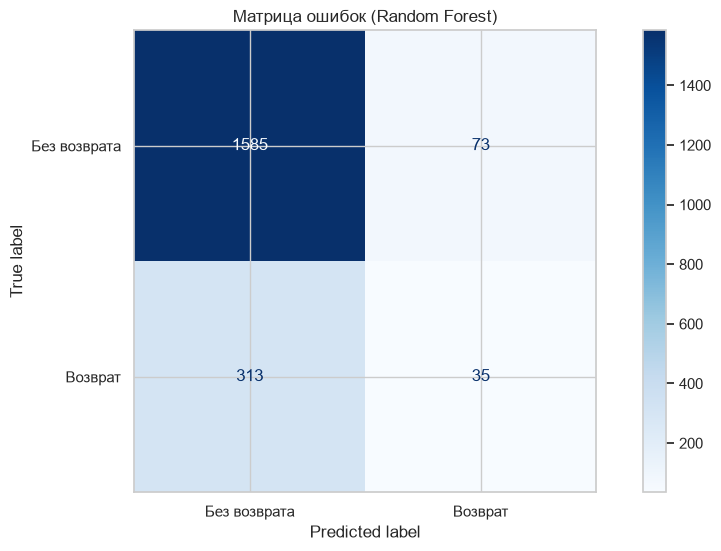

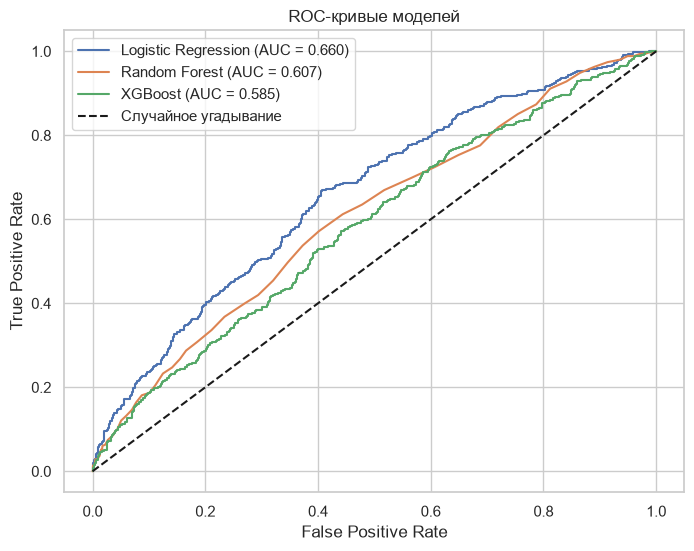

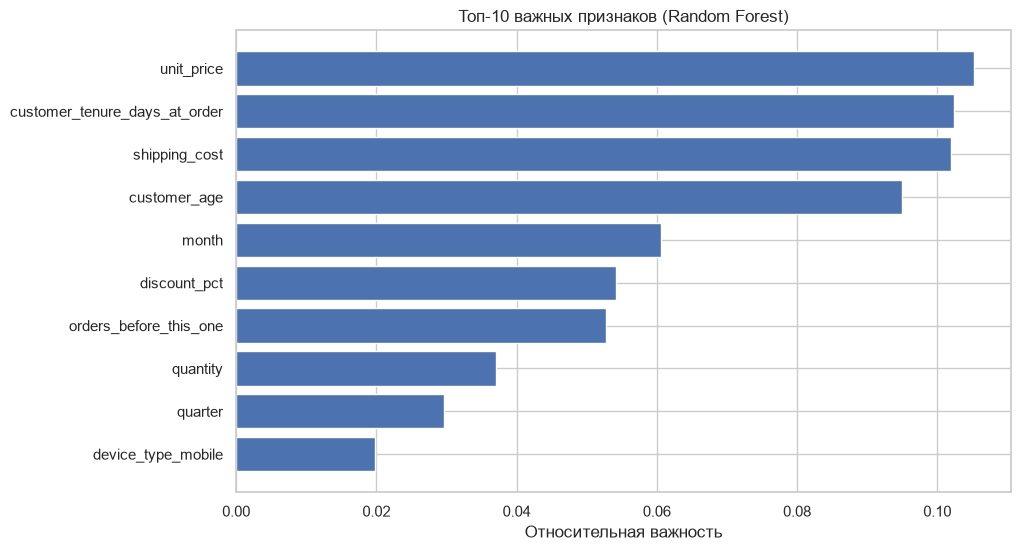


=== ИНТЕРПРЕТАЦИЯ (Statsmodels) ===
                           Logit Regression Results                           
Dep. Variable:            is_returned   No. Observations:                 8020
Model:                          Logit   Df Residuals:                     8009
Method:                           MLE   Df Model:                           10
Date:                Thu, 05 Nov 2026   Pseudo R-squ.:                 0.02240
Time:                        21:17:14   Log-Likelihood:                -3616.8
converged:                       True   LL-Null:                       -3699.6
Covariance Type:            nonrobust   LLR p-value:                 2.142e-30
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const                           157.7052    183.641      0.859      0.390    -202.225     517.635
unit_price                       -0.0

In [4]:
print("\n--- ГЛАВА 3: МАШИННОЕ ОБУЧЕНИЕ ---")

# 1. НАСТРОЙКА ПУТЕЙ
base_dir = os.getcwd()
output_dir = os.path.join(base_dir, 'output')
os.makedirs(output_dir, exist_ok=True)
print(f"📁 Графики будут сохранены в: {output_dir}")

filename = 'cleaned_ecommerce_data.csv'
data_path = os.path.join(output_dir, filename)

if not os.path.exists(data_path):
    raise FileNotFoundError(f"❌ Файл '{filename}' не найден в папке output!")

print(f"✅ Данные найдены: {data_path}")

# 2. ЗАГРУЗКА И ПОДГОТОВКА ДАННЫХ
df_ml = pd.read_csv(data_path)

cols_to_drop = [
    'order_id', 'customer_id', 'order_date', 'signup_date', 
    'total_amount', 'return_reason', 'refund_amount', 
    'customer_support_ticket_after_order', # УБРАНА УТЕЧКА ДАННЫХ
    'is_returned'
]
X = df_ml.drop(columns=cols_to_drop, errors='ignore')
y = df_ml['is_returned']

# One-Hot Encoding
X = pd.get_dummies(X, drop_first=True)

# Разделение на train/test (80/20) со стратификацией
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Масштабирование для логистической регрессии
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. ОБУЧЕНИЕ МОДЕЛЕЙ
print("\n⏳ Обучение моделей...")

# Модель 1: Логистическая регрессия
lr = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_test_scaled)
y_prob_lr = lr.predict_proba(X_test_scaled)[:, 1]

# Модель 2: Random Forest
rf = RandomForestClassifier(class_weight='balanced', random_state=42, n_estimators=100)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

# Модель 3: XGBoost
scale_pos_weight = (len(y_train) - sum(y_train)) / sum(y_train)
xgb = XGBClassifier(scale_pos_weight=scale_pos_weight, random_state=42, eval_metric='logloss')
xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict(X_test)
y_prob_xgb = xgb.predict_proba(X_test)[:, 1]

# 4. МЕТРИКИ
print("\n=== МЕТРИКИ МОДЕЛЕЙ ===")
for name, y_pred, y_prob in [("Logistic Regression", y_pred_lr, y_prob_lr), 
                             ("Random Forest", y_pred_rf, y_prob_rf), 
                             ("XGBoost", y_pred_xgb, y_prob_xgb)]:
    print(f"\n--- {name} ---")
    print(classification_report(y_test, y_pred))
    print(f"ROC-AUC: {roc_auc_score(y_test, y_prob):.4f}")

# 5. ГРАФИКИ
print("\n📊 Построение и сохранение графиков...")

# График 4: Матрица ошибок
plt.figure(figsize=(6, 4))
cm = confusion_matrix(y_test, y_pred_rf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Без возврата', 'Возврат'])
disp.plot(cmap='Blues', values_format='d')
plt.title('Матрица ошибок (Random Forest)')
plt.savefig(os.path.join(output_dir, 'Figure_4_Confusion_Matrix.png'), dpi=300, bbox_inches='tight')
plt.show()

# График 5: ROC-кривые
plt.figure(figsize=(8, 6))
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb)

plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {roc_auc_score(y_test, y_prob_lr):.3f})')
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {roc_auc_score(y_test, y_prob_rf):.3f})')
plt.plot(fpr_xgb, tpr_xgb, label=f'XGBoost (AUC = {roc_auc_score(y_test, y_prob_xgb):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Случайное угадывание')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривые моделей')
plt.legend()
plt.savefig(os.path.join(output_dir, 'Figure_5_ROC_Curve.png'), dpi=300, bbox_inches='tight')
plt.show()

# График 6: Важность признаков
importances = rf.feature_importances_
indices = np.argsort(importances)[-10:] 
plt.figure(figsize=(10, 6))
plt.title('Топ-10 важных признаков (Random Forest)')
plt.barh(range(len(indices)), importances[indices], color='b', align='center')
plt.yticks(range(len(indices)), [X.columns[i] for i in indices])
plt.xlabel('Относительная важность')
plt.savefig(os.path.join(output_dir, 'Figure_6_Feature_Importance.png'), dpi=300, bbox_inches='tight')
plt.show()

# 6. ИНТЕРПРЕТАЦИЯ (STATSMODELS)
print("\n=== ИНТЕРПРЕТАЦИЯ (Statsmodels) ===")
X_sm = X_train.select_dtypes(include=[np.number])
X_sm = sm.add_constant(X_sm)
logit_model = sm.Logit(y_train, X_sm).fit(disp=False)

# ПОЛНЫЙ ВЫВОД СВОДКИ STATSMODELS
print(logit_model.summary())

print(f"\n✅ ВСЁ ГОТОВО! Все графики и таблицы сохранены в папку 'output'.")